<a href="https://colab.research.google.com/github/DinaKSari/244107020072-mobile-course/blob/main/PBL_KLUSTERING_HIERARKI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K Means Euclidean

# Langkah 1: Setup & Import

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

import time
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

MIN_SAMPLES = 10  # ambang minimum anggota per klaster (dipakai sebagai pengecekan di evaluasi)

# Langkah 2: Load Dataset


In [2]:
df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')

print(f"Total data awal: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Total data awal: 3169 baris, 9 kolom


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


### Informasi & Eksplorasi Dataset Awal

In [3]:
import pandas as pd
print("Ukuran Dataset:", df.shape)
print("\nNama Kolom:", df.columns.tolist())
print("\nInformasi Dataset:")
df.info()
print("\nJumlah Missing Value:")
print(df.isnull().sum())

Ukuran Dataset: (3169, 9)

Nama Kolom: ['Plant_ID', 'Date', 'Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days', 'Temperature (F)', 'Humidity']

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB

Jumlah Missing Value:
Plant_ID            0
Date                0
Temperature (°C)    0
Humidity (%)        0
TDS Value

# Langkah 3: Preprocessing, seleksi fitur, standarisasi, dan Fungsi Pembagian Data

In [4]:
features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
X_raw = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
df_scaled = pd.DataFrame(X_scaled, columns=features)

def get_data_splits(data):
    splits = {
        "Full Data (100%)": data.values,
        "80% Data": data.sample(frac=0.8, random_state=42).values,
        "50% Data": data.sample(frac=0.5, random_state=42).values,
        "30% Data": data.sample(frac=0.3, random_state=42).values
    }
    return splits

data_splits = get_data_splits(df_scaled)

for name, data in data_splits.items():
    print(f"{name}: {len(data)} baris")

Full Data (100%): 3169 baris
80% Data: 2535 baris
50% Data: 1584 baris
30% Data: 951 baris


# Langkah 4: Euclidean Distance (K-Means)

In [5]:
class CustomKMeans:
    def __init__(self, n_clusters=3, max_iters=100, metric='euclidean'):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.metric = metric
        self.centroids = None
        self.labels = None
        self.inertia_ = 0

    def fit(self, X):
        np.random.seed(42)
        random_idx = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[random_idx]

        for _ in range(self.max_iters):
            distances = cdist(X, self.centroids, metric=self.metric)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros((self.n_clusters, X.shape[1]))
            for i in range(self.n_clusters):
                cluster_data = X[self.labels == i]
                if len(cluster_data) > 0:
                    new_centroids[i] = np.mean(cluster_data, axis=0)
                else:
                    new_centroids[i] = self.centroids[i]

            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids

        final_dist = cdist(X, self.centroids, metric=self.metric)
        min_dist = np.min(final_dist, axis=1)
        self.inertia_ = np.sum(min_dist**2)

        return self

# Langkah 5: Elbow Method

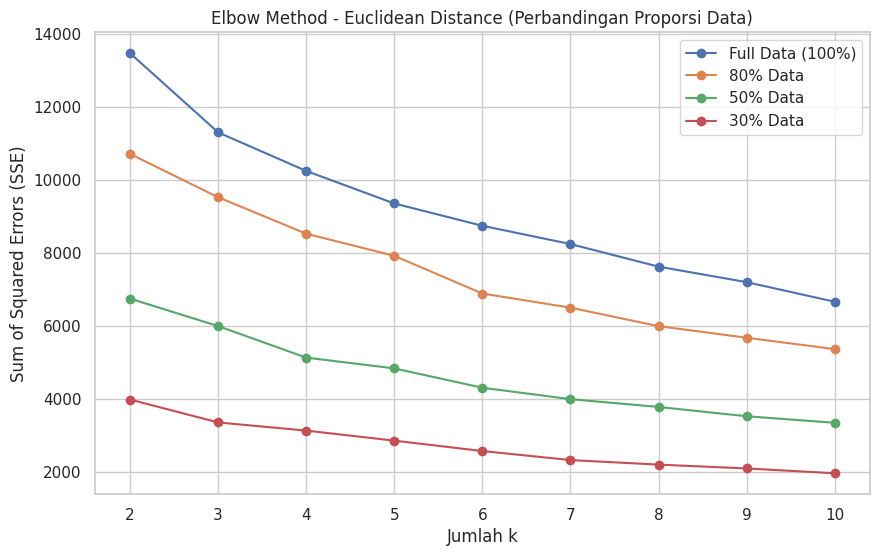

In [6]:
plt.figure(figsize=(10, 6))
K_range = range(2, 11)

for name, X_data in data_splits.items():
    sse = []
    for k in K_range:
        model = CustomKMeans(n_clusters=k, metric='euclidean')
        model.fit(X_data)
        sse.append(model.inertia_)
    plt.plot(K_range, sse, marker='o', label=name)

plt.xlabel('Jumlah k')
plt.ylabel('Sum of Squared Errors (SSE)')
plt.title('Elbow Method - Euclidean Distance (Perbandingan Proporsi Data)')
plt.legend()
plt.xticks(K_range)
plt.show()

# Langkah 6: Clustering Final + Metrik Evaluasi

In [7]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
def eval3(X, labels):
    return (silhouette_score(X, labels), davies_bouldin_score(X, labels), calinski_harabasz_score(X, labels))

k_optimal = 4
euclidean_results, rows = {}, []
for name, X_data in data_splits.items():
    model = CustomKMeans(n_clusters=k_optimal, metric='euclidean')
    t0 = time.perf_counter(); model.fit(X_data); t = time.perf_counter() - t0
    sil, db, ch = eval3(X_data, model.labels)
    euclidean_results[name] = sil
    rows.append({'Proporsi Data': name, 'Jumlah Sampel': len(X_data), 'Cluster': k_optimal,
                 'Silhouette Score': round(sil,4), 'Davies-Bouldin': round(db,4),
                 'Calinski-Harabasz': round(ch,2), 'Waktu Eksekusi (s)': round(t,5)})
euclid_df = pd.DataFrame(rows)
euclid_df


,Proporsi Data,Jumlah Sampel,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,Full Data (100%),3169,4,0.1547,1.6698,574.59,0.02616
1,80% Data,2535,4,0.1527,1.7526,402.44,0.12395
2,50% Data,1584,4,0.1576,1.6926,286.69,0.09945
3,30% Data,951,4,0.1775,1.9502,159.05,0.02337


# Langkah 7: Visualisasi Pca 2D Pemetaan Klaster

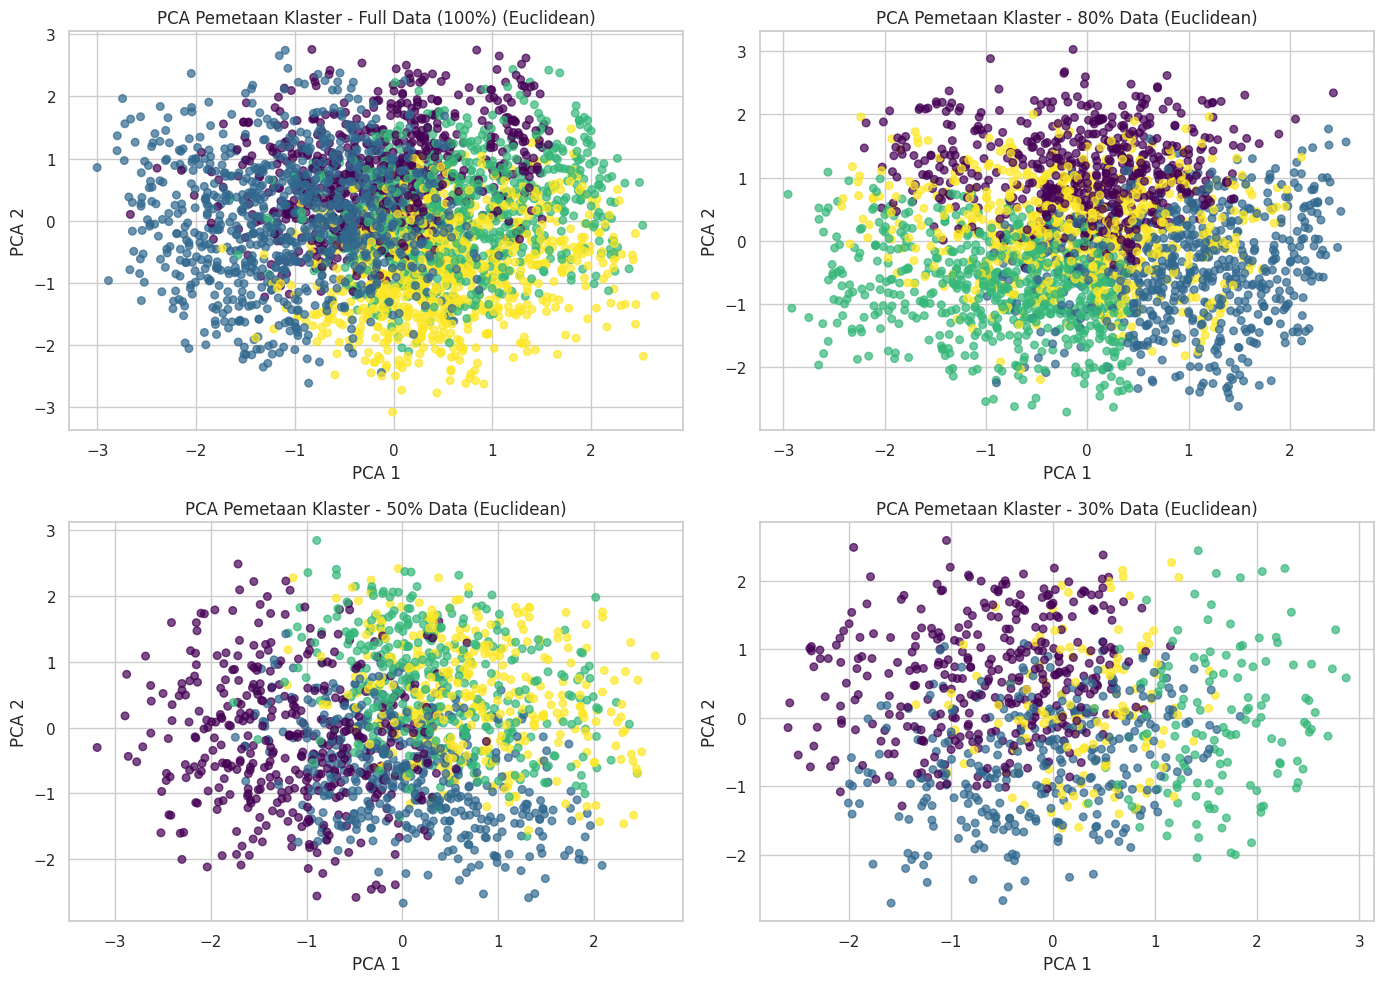

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, (name, X_data) in enumerate(data_splits.items()):
    model = CustomKMeans(n_clusters=k_optimal, metric='euclidean')
    model.fit(X_data)

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_data)

    scatter = axes[idx].scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels, cmap='viridis', s=30, alpha=0.7)
    axes[idx].set_title(f'PCA Pemetaan Klaster - {name} (Euclidean)')
    axes[idx].set_xlabel('PCA 1')
    axes[idx].set_ylabel('PCA 2')

plt.tight_layout()
plt.show()

# Langkah 8: Grafik Bar Perbandingan Metrik

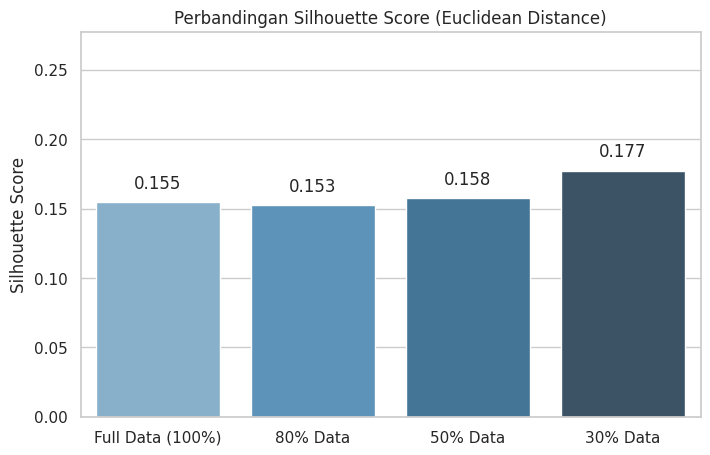

In [9]:
names = list(euclidean_results.keys())
scores = list(euclidean_results.values())

plt.figure(figsize=(8, 5))
sns.barplot(x=names, y=scores, palette='Blues_d')
plt.title('Perbandingan Silhouette Score (Euclidean Distance)')
plt.ylabel('Silhouette Score')
plt.ylim(0, max(scores) + 0.1)

for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f'{score:.3f}', ha='center')

plt.show()

# Metode Manhattan Distance

# Langkah 1: Setup & Import

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import cdist

import time
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

MIN_SAMPLES = 10  # ambang minimum anggota per klaster (dipakai sebagai pengecekan di evaluasi)

# Langkah 2: Load Dataset

In [11]:
df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')
print(f"Total data awal: {df.shape[0]} baris, {df.shape[1]} kolom")

Total data awal: 3169 baris, 9 kolom


# Langkah 3: Preprocessing + Fungsi Pembagian Data

In [12]:
features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
X_raw = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)
df_scaled = pd.DataFrame(X_scaled, columns=features)

def get_data_splits(data):
    splits = {
        "Full Data (100%)": data.values,
        "80% Data": data.sample(frac=0.8, random_state=42).values,
        "50% Data": data.sample(frac=0.5, random_state=42).values,
        "30% Data": data.sample(frac=0.3, random_state=42).values
    }
    return splits

data_splits = get_data_splits(df_scaled)

# Langkah 4: Manhattan Distance (K-Medians)

In [13]:
class CustomKMedians:
    def __init__(self, n_clusters=3, max_iters=100, metric='cityblock'):
        self.n_clusters = n_clusters
        self.max_iters = max_iters
        self.metric = metric
        self.centroids = None
        self.labels = None
        self.inertia_ = 0

    def fit(self, X):
        np.random.seed(42)
        random_idx = np.random.choice(len(X), self.n_clusters, replace=False)
        self.centroids = X[random_idx]

        for _ in range(self.max_iters):
            distances = cdist(X, self.centroids, metric=self.metric)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros((self.n_clusters, X.shape[1]))
            for i in range(self.n_clusters):
                cluster_data = X[self.labels == i]
                if len(cluster_data) > 0:
                    new_centroids[i] = np.median(cluster_data, axis=0)
                else:
                    new_centroids[i] = self.centroids[i]

            if np.allclose(self.centroids, new_centroids):
                break
            self.centroids = new_centroids

        # Hitung Error absolut
        final_dist = cdist(X, self.centroids, metric=self.metric)
        self.inertia_ = np.sum(np.min(final_dist, axis=1))

        return self

# Langkah 5: Elbow Method


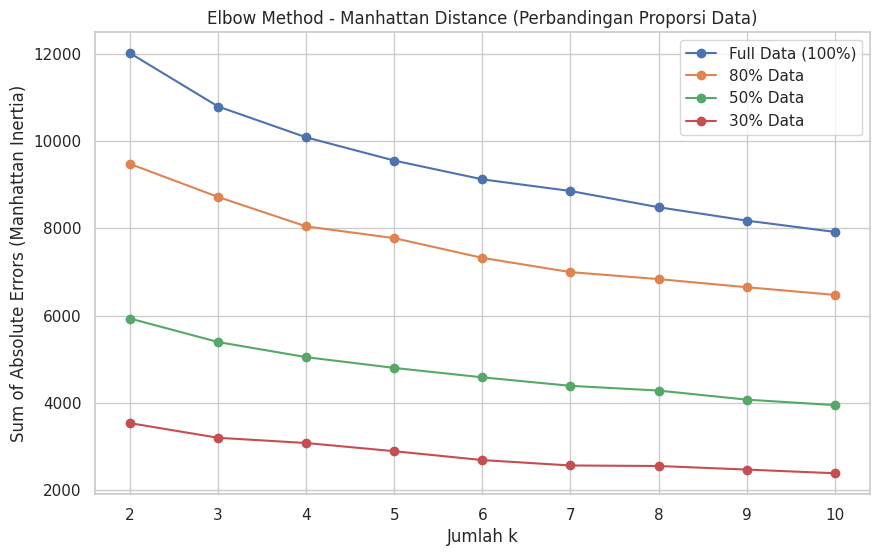

In [14]:
plt.figure(figsize=(10, 6))
K_range = range(2, 11)

for name, X_data in data_splits.items():
    sse = []
    for k in K_range:
        model = CustomKMedians(n_clusters=k, metric='cityblock')
        model.fit(X_data)
        sse.append(model.inertia_)
    plt.plot(K_range, sse, marker='o', label=name)

plt.xlabel('Jumlah k')
plt.ylabel('Sum of Absolute Errors (Manhattan Inertia)')
plt.title('Elbow Method - Manhattan Distance (Perbandingan Proporsi Data)')
plt.legend()
plt.xticks(K_range)
plt.show()

# Langkah 6: Clustering Final + Metrik Evaluasi

In [15]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
def eval3(X, labels):
    return (silhouette_score(X, labels), davies_bouldin_score(X, labels), calinski_harabasz_score(X, labels))

k_optimal = 4
manhattan_results, rows = {}, []
for name, X_data in data_splits.items():
    model = CustomKMedians(n_clusters=k_optimal, metric='cityblock')
    t0 = time.perf_counter(); model.fit(X_data); t = time.perf_counter() - t0
    sil, db, ch = eval3(X_data, model.labels)   # metrik Euclidean agar seragam antar metode
    manhattan_results[name] = sil
    rows.append({'Proporsi Data': name, 'Jumlah Sampel': len(X_data), 'Cluster': k_optimal,
                 'Silhouette Score': round(sil,4), 'Davies-Bouldin': round(db,4),
                 'Calinski-Harabasz': round(ch,2), 'Waktu Eksekusi (s)': round(t,5)})
manhattan_df = pd.DataFrame(rows)
manhattan_df


,Proporsi Data,Jumlah Sampel,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,Full Data (100%),3169,4,0.1430,1.7580,518.45,0.01298
1,80% Data,2535,4,0.1324,1.8431,398.56,0.01251
2,50% Data,1584,4,0.1417,1.7816,255.45,0.00984
3,30% Data,951,4,0.1368,2.0985,130.15,0.00964


# Langkah 7: Visualisasi Pca 2D Pemetaan Klaster


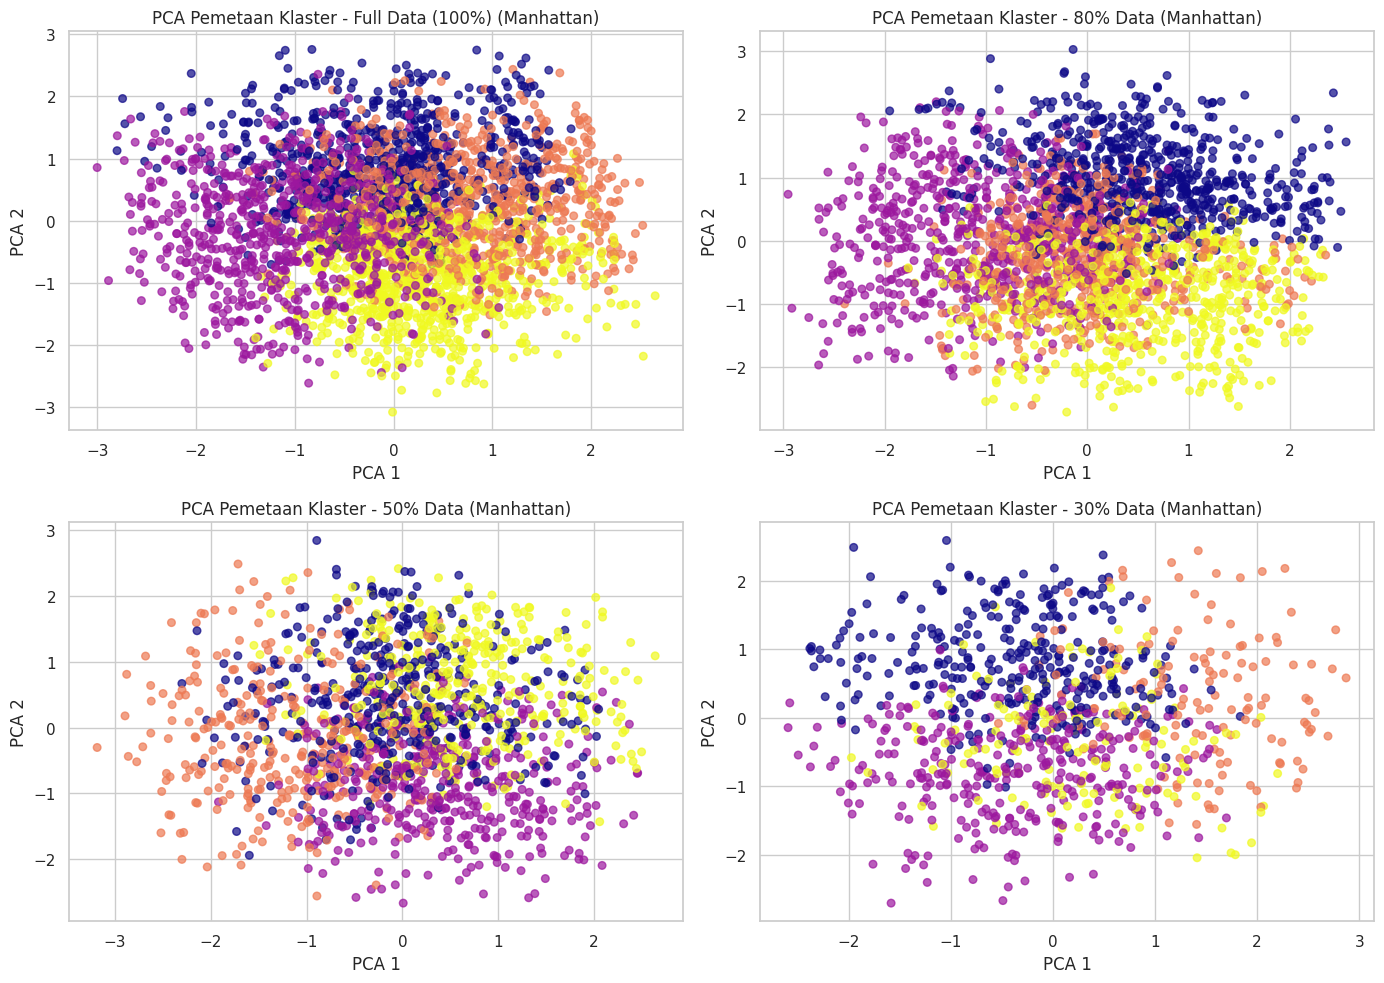

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, (name, X_data) in enumerate(data_splits.items()):
    model = CustomKMedians(n_clusters=k_optimal, metric='cityblock')
    model.fit(X_data)

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_data)

    scatter = axes[idx].scatter(X_pca[:, 0], X_pca[:, 1], c=model.labels, cmap='plasma', s=30, alpha=0.7)
    axes[idx].set_title(f'PCA Pemetaan Klaster - {name} (Manhattan)')
    axes[idx].set_xlabel('PCA 1')
    axes[idx].set_ylabel('PCA 2')

plt.tight_layout()
plt.show()

# Langkah 8: Grafik Bar Perbandingan Metrik


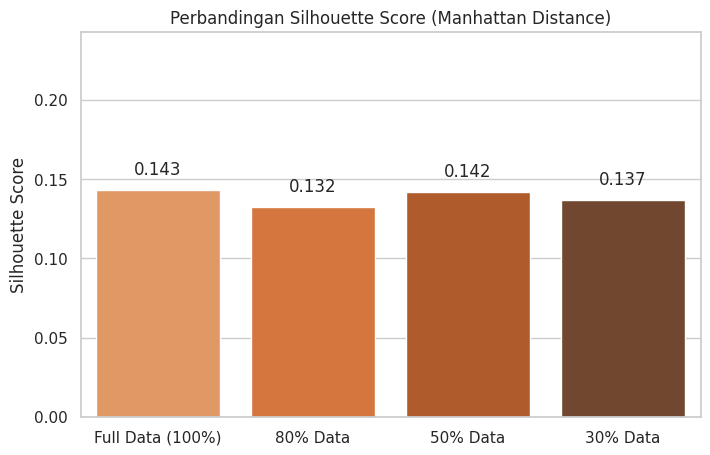

In [17]:
names = list(manhattan_results.keys())
scores = list(manhattan_results.values())

plt.figure(figsize=(8, 5))
sns.barplot(x=names, y=scores, palette='Oranges_d')
plt.title('Perbandingan Silhouette Score (Manhattan Distance)')
plt.ylabel('Silhouette Score')
plt.ylim(0, max(scores) + 0.1)

for i, score in enumerate(scores):
    plt.text(i, score + 0.01, f'{score:.3f}', ha='center')

plt.show()

# Cosine Similarity

In [18]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, pairwise_distances)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
K = 4
MIN_SAMPLES = 10

In [19]:
# encoding latin1 karena ada simbol derajat (°) pada nama kolom
df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')
df.columns = df.columns.str.strip()

print(f"Total data awal: {df.shape[0]} baris, {df.shape[1]} kolom")
print(f"Missing value total: {int(df.isna().sum().sum())}")
df.head()

Total data awal: 3169 baris, 9 kolom
Missing value total: 0


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [20]:
features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']

# Preprocessing SERAGAM untuk semua metode (apple to apple): hanya StandardScaler
preprocess = StandardScaler()

SPLITS = {"Full Data (100%)": 1.0, "80% Data": 0.8, "50% Data": 0.5, "30% Data": 0.3}

def get_data_splits(data):
    return {name: preprocess.fit_transform(
                (data if frac == 1 else data.sample(frac=frac, random_state=RANDOM_STATE)).sort_index()[features])
            for name, frac in SPLITS.items()}

data_splits = get_data_splits(df)

for name, X in data_splits.items():
    print(f"{name:<18}: {X.shape[0]:>5} baris x {X.shape[1]} fitur")

Full Data (100%)  :  3169 baris x 5 fitur
80% Data          :  2535 baris x 5 fitur
50% Data          :  1584 baris x 5 fitur
30% Data          :   951 baris x 5 fitur


In [21]:
class KMeansCosine:
    """Assignment pakai Cosine Distance, centroid = rata-rata ter-normalisasi."""
    def __init__(self, n_clusters=3, max_iter=300, tol=1e-4, random_state=RANDOM_STATE):
        self.n_clusters, self.max_iter, self.tol, self.random_state = n_clusters, max_iter, tol, random_state

    def _dist(self, X, C):
        return pairwise_distances(X, C, metric='cosine')

    def fit(self, X):
        X, n = normalize(X), len(X)   # normalisasi L2 bagian dari algoritma spherical, bukan preprocessing

        # Inisialisasi centroid ala k-means++ (jarak cosine)
        rng = np.random.RandomState(self.random_state)
        C = [X[rng.randint(n)]]
        for _ in range(self.n_clusters - 1):
            d = self._dist(X, np.array(C)).min(axis=1) ** 2
            C.append(X[rng.choice(n, p=np.ones(n) / n if d.sum() == 0 else d / d.sum())])
        self.centroids = normalize(np.array(C))

        rng = np.random.RandomState(self.random_state)  # dipakai jika ada klaster kosong
        for self.n_iter_ in range(1, self.max_iter + 1):
            labels = self._dist(X, self.centroids).argmin(axis=1)
            new_c = np.array([normalize(X[labels == k].mean(axis=0, keepdims=True))[0] if (labels == k).any()
                              else X[rng.randint(n)] for k in range(self.n_clusters)])
            shift = np.linalg.norm(new_c - self.centroids)
            self.centroids, self.labels_ = new_c, labels
            if shift <= self.tol:
                break

        self.inertia_ = self._dist(X, self.centroids)[np.arange(n), self.labels_].sum()
        return self

def run_method(model, X):
    """Jalankan satu metode, kembalikan (label, waktu proses dalam detik)."""
    t0 = time.perf_counter()
    labels = model.fit(X).labels_
    return labels, time.perf_counter() - t0

# Daftar metode: tiap langkah menambahkan satu metode
# (X dikirim agar parameter, misalnya eps DBSCAN, bisa menyesuaikan data)
METHODS = {"K-Means (Cosine)": lambda X: KMeansCosine(n_clusters=K)}

In [22]:
# --- K-Means (Euclidean) & Hierarchical (Ward): jumlah klaster tetap K ---
METHODS["K-Means (Euclidean)"] = lambda X: KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
METHODS["Hierarchical (Ward)"] = lambda X: AgglomerativeClustering(n_clusters=K, linkage='ward')

# --- DBSCAN: jumlah klaster otomatis, eps dicari dari grafik k-distance ---
def find_elbow_point(k_vals, inertias):
    """Titik dengan jarak terjauh dari garis lurus (k_awal -> k_akhir)."""
    pts = np.column_stack([k_vals, inertias]).astype(float)
    u = (pts[-1] - pts[0]) / np.linalg.norm(pts[-1] - pts[0])
    v = pts - pts[0]
    return k_vals[np.argmax(np.linalg.norm(v - np.outer(v @ u, u), axis=1))]

def estimate_eps(X, min_samples=MIN_SAMPLES):
    """Eps DBSCAN dari grafik k-distance: titik siku jarak ke tetangga ke-min_samples."""
    d = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)[0][:, -1])
    return d[find_elbow_point(np.arange(len(d)), d)]

METHODS["DBSCAN"] = lambda X: DBSCAN(eps=0.64, min_samples=10)
print("[INFO] Metode siap:", list(METHODS))

[INFO] Metode siap: ['K-Means (Cosine)', 'K-Means (Euclidean)', 'Hierarchical (Ward)', 'DBSCAN']


k hasil elbow (Full Data 100%) = 4 | k yang digunakan semua metode = 4
-------------------------------------------------------
Full Data (100%)   -> k digunakan = 4 (inertia = 1251.48)
80% Data           -> k digunakan = 4 (inertia = 987.39)
50% Data           -> k digunakan = 4 (inertia = 614.25)
30% Data           -> k digunakan = 4 (inertia = 366.85)


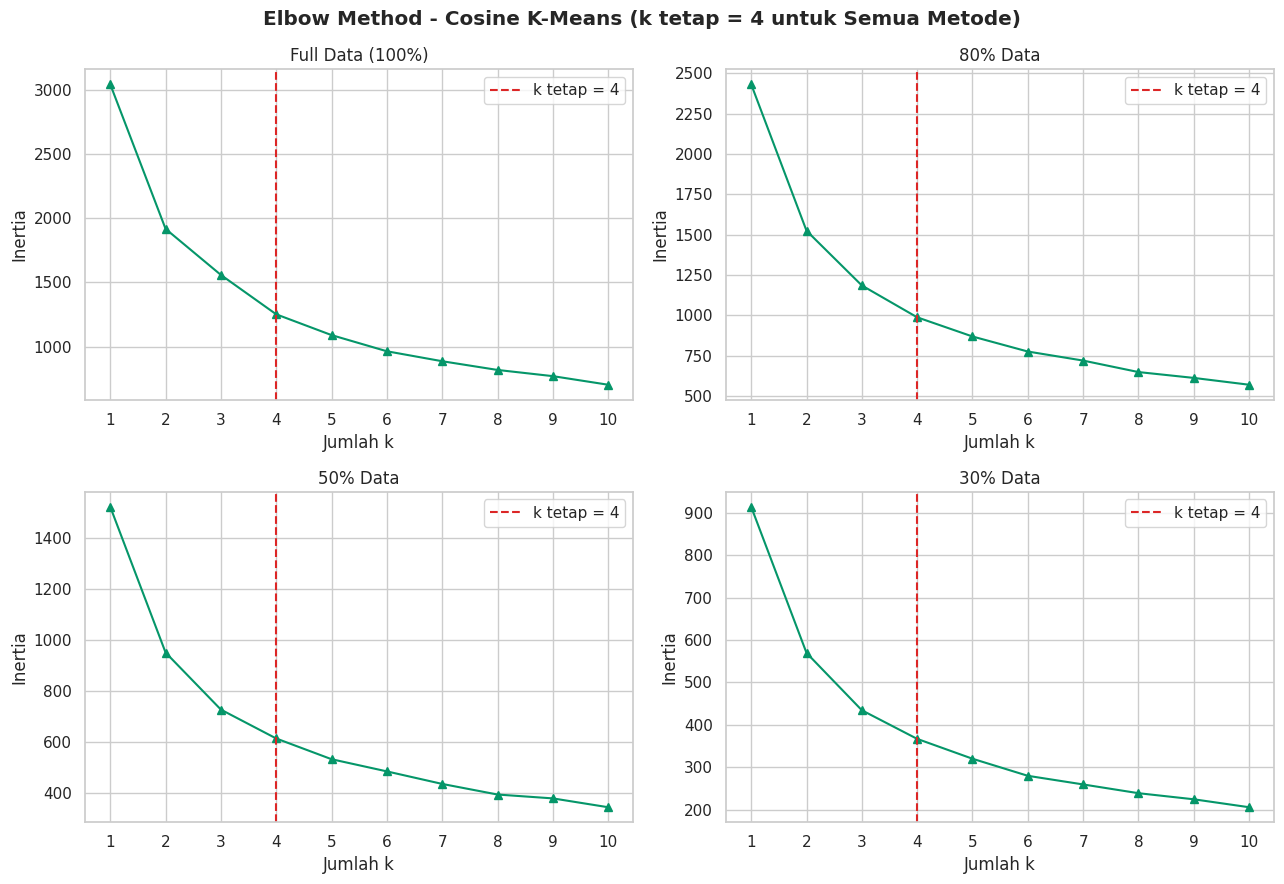

In [23]:
K_range = list(range(1, 11))

# Kurva elbow (Cosine K-Means) tiap proporsi data; k yang dipakai semua metode dikunci = K
sse_all = {name: [KMeansCosine(k, max_iter=200).fit(X).inertia_ for k in K_range]
           for name, X in data_splits.items()}
elbow_k = find_elbow_point(K_range, sse_all["Full Data (100%)"])

print(f"k hasil elbow (Full Data 100%) = {elbow_k} | k yang digunakan semua metode = {K}")
print("-" * 55)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, sse) in zip(axes.ravel(), sse_all.items()):
    print(f"{name:<18} -> k digunakan = {K} (inertia = {sse[K - 1]:.2f})")
    ax.plot(K_range, sse, marker='^', color='#059669')
    ax.axvline(K, color='#DC2626', linestyle='--', label=f'k tetap = {K}')
    ax.set(title=name, xlabel='Jumlah k', ylabel='Inertia', xticks=K_range)
    ax.legend()

plt.suptitle(f'Elbow Method - Cosine K-Means (k tetap = {K} untuk Semua Metode)', fontweight='bold')
plt.tight_layout()
plt.show()

In [24]:
def evaluate(X, labels):
    """Metrik seragam (jarak Euclidean pada data StandardScaler) untuk semua metode.
    Titik noise DBSCAN (-1) diabaikan; butuh minimal 2 klaster, jika tidak -> NaN."""
    m = labels != -1
    if len(set(labels[m])) < 2:
        return [np.nan] * 3
    return [silhouette_score(X[m], labels[m]), davies_bouldin_score(X[m], labels[m]),
            calinski_harabasz_score(X[m], labels[m])]

results, rows = {}, []
for name, X in data_splits.items():
    for mname, make in METHODS.items():
        labels, t = run_method(make(X), X)
        results[(name, mname)] = labels
        sil, db, ch = evaluate(X, labels)
        rows.append({
            'Skenario Data': name,
            'Metode': mname,
            'Jumlah Sampel': len(X),
            'Cluster (k)': K if mname != 'DBSCAN' else '-',
            'min_samples': 10 if mname == 'DBSCAN' else '-',
            'eps': 0.64 if mname == 'DBSCAN' else '-',
            'Noise': int((labels == -1).sum()),
            'Silhouette Score (↑)': round(sil, 4),
            'Davies-Bouldin Index (↓)': round(db, 4),
            'Calinski-Harabasz Index (↑)': round(ch, 2),
            'Waktu Eksekusi (s) (↓)': round(t, 5),
        })

eval_df = pd.DataFrame(rows)
eval_df

,Skenario Data,Metode,Jumlah Sampel,Cluster (k),min_samples,eps,Noise,Silhouette Score (↑),Davies-Bouldin Index (↓),Calinski-Harabasz Index (↑),Waktu Eksekusi (s) (↓)
0,Full Data (100%),K-Means (Cosine),3169,4,-,-,0,0.1501,1.6919,565.48,0.04531
1,Full Data (100%),K-Means (Euclidean),3169,4,-,-,0,0.1570,1.6558,578.82,0.06033
2,Full Data (100%),Hierarchical (Ward),3169,4,-,-,0,0.1193,1.9496,484.75,0.19315
3,Full Data (100%),DBSCAN,3169,-,10,0.64,1358,-0.0019,0.9083,17.10,0.03783
4,80% Data,K-Means (Cosine),2535,4,-,-,0,0.1533,1.6649,459.71,0.05604
5,80% Data,K-Means (Euclidean),2535,4,-,-,0,0.1576,1.6812,461.80,0.03175
6,80% Data,Hierarchical (Ward),2535,4,-,-,0,0.1159,1.9020,382.86,0.11784
7,80% Data,DBSCAN,2535,-,10,0.64,1434,-0.1966,1.1866,27.09,0.02664
8,50% Data,K-Means (Cosine),1584,4,-,-,0,0.1569,1.6537,289.76,0.07058
9,50% Data,K-Means (Euclidean),1584,4,-,-,0,0.1605,1.6542,293.37,0.04736


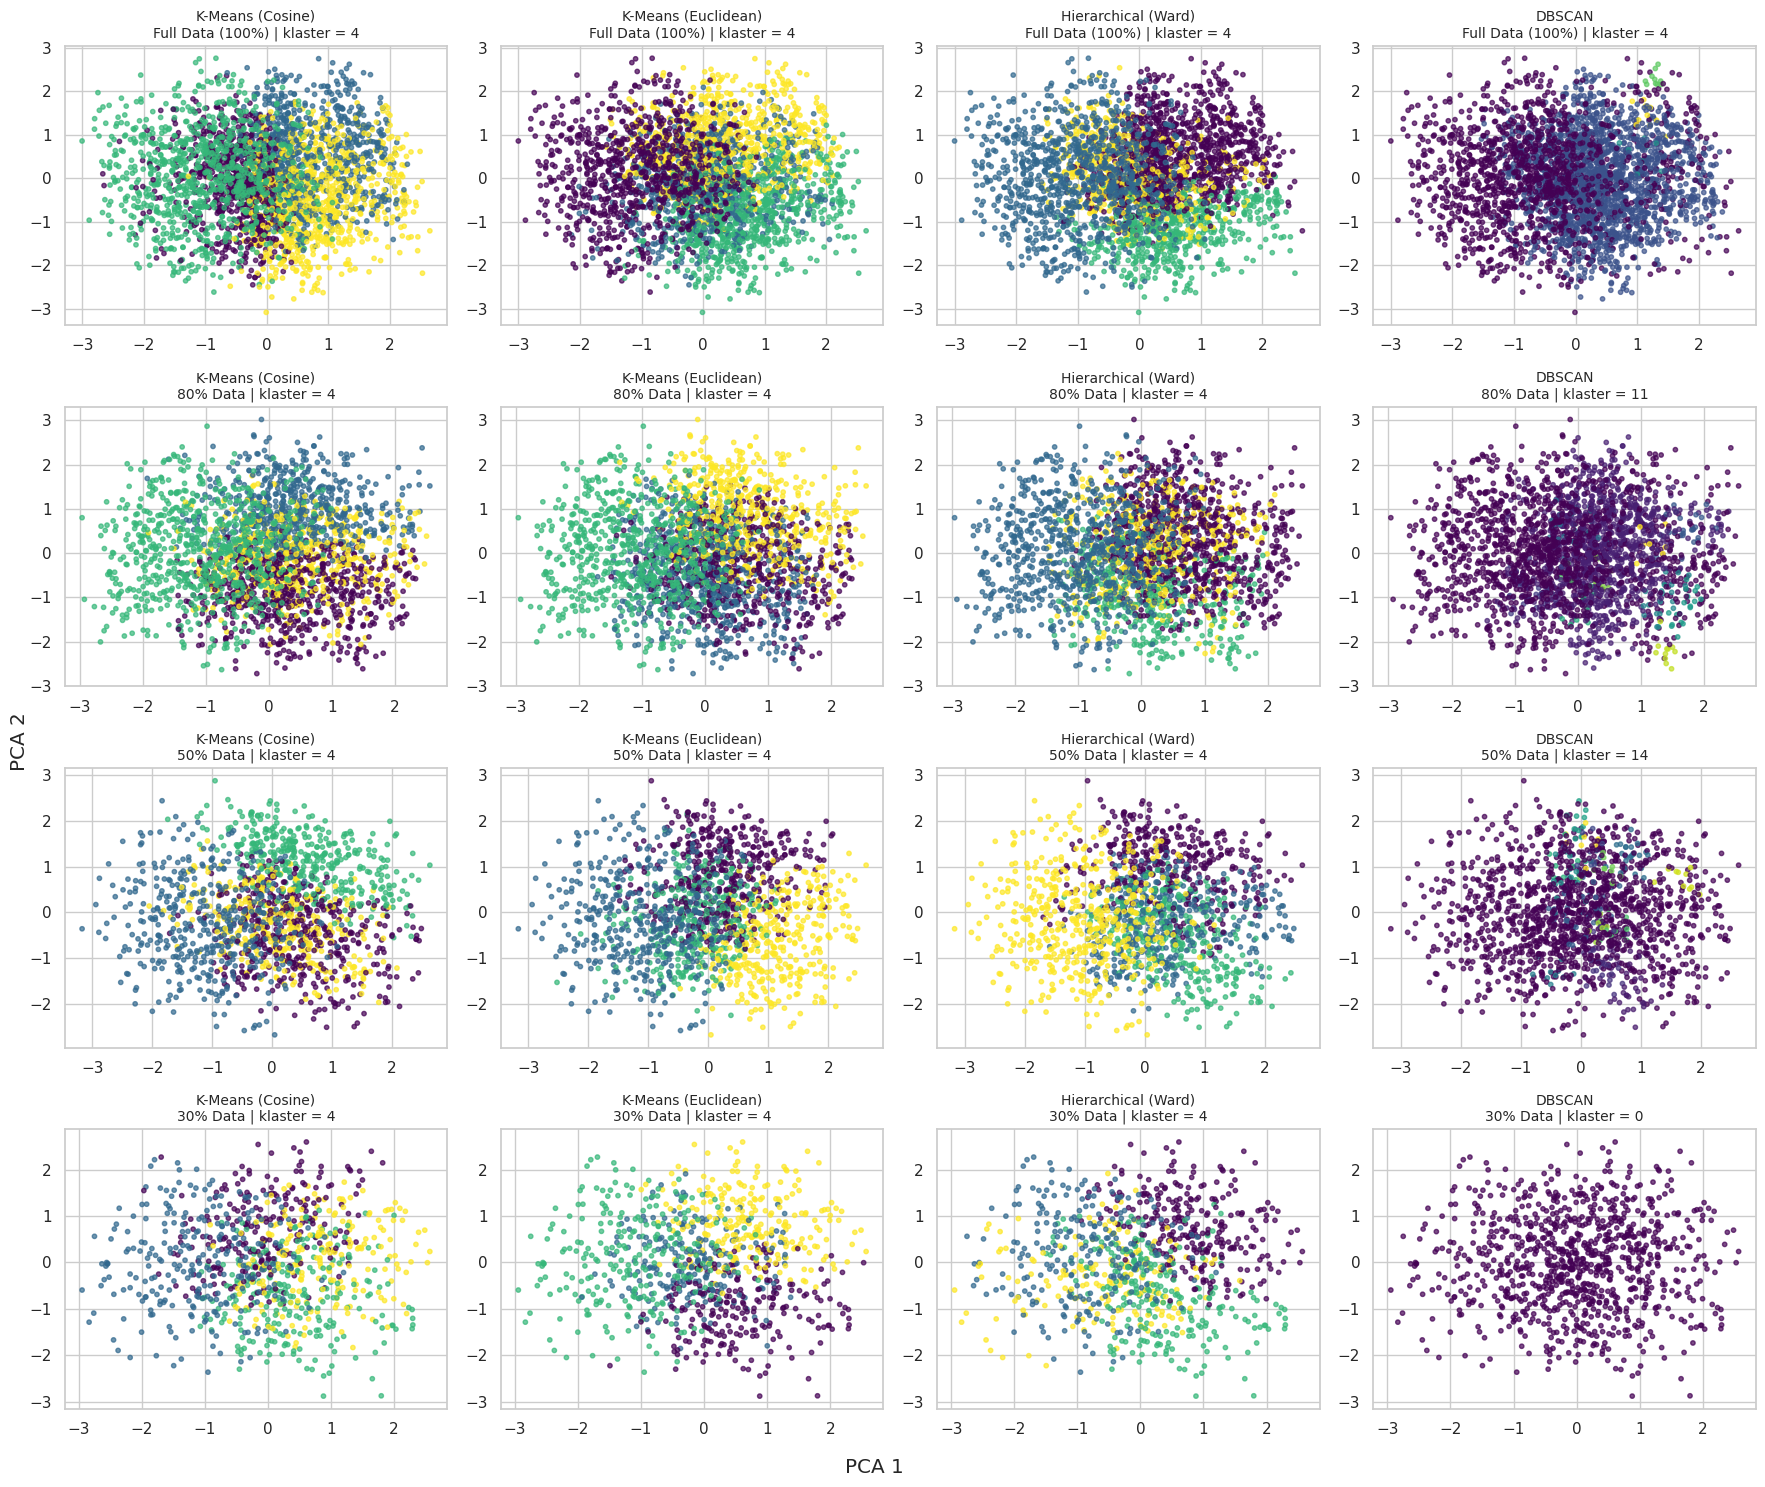

In [25]:
fig, axes = plt.subplots(len(data_splits), len(METHODS), figsize=(18, 15))
for i, (name, X) in enumerate(data_splits.items()):
    Z = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)   # proyeksi sama untuk semua metode
    for j, mname in enumerate(METHODS):
        labels = results[(name, mname)]
        axes[i, j].scatter(*Z.T, c=labels, cmap='viridis', s=10, alpha=0.7)
        axes[i, j].set_title(f'{mname}\n{name} | klaster = {len(set(labels) - {-1})}', fontsize=10)

fig.supxlabel('PCA 1'); fig.supylabel('PCA 2')
plt.tight_layout()
plt.show()



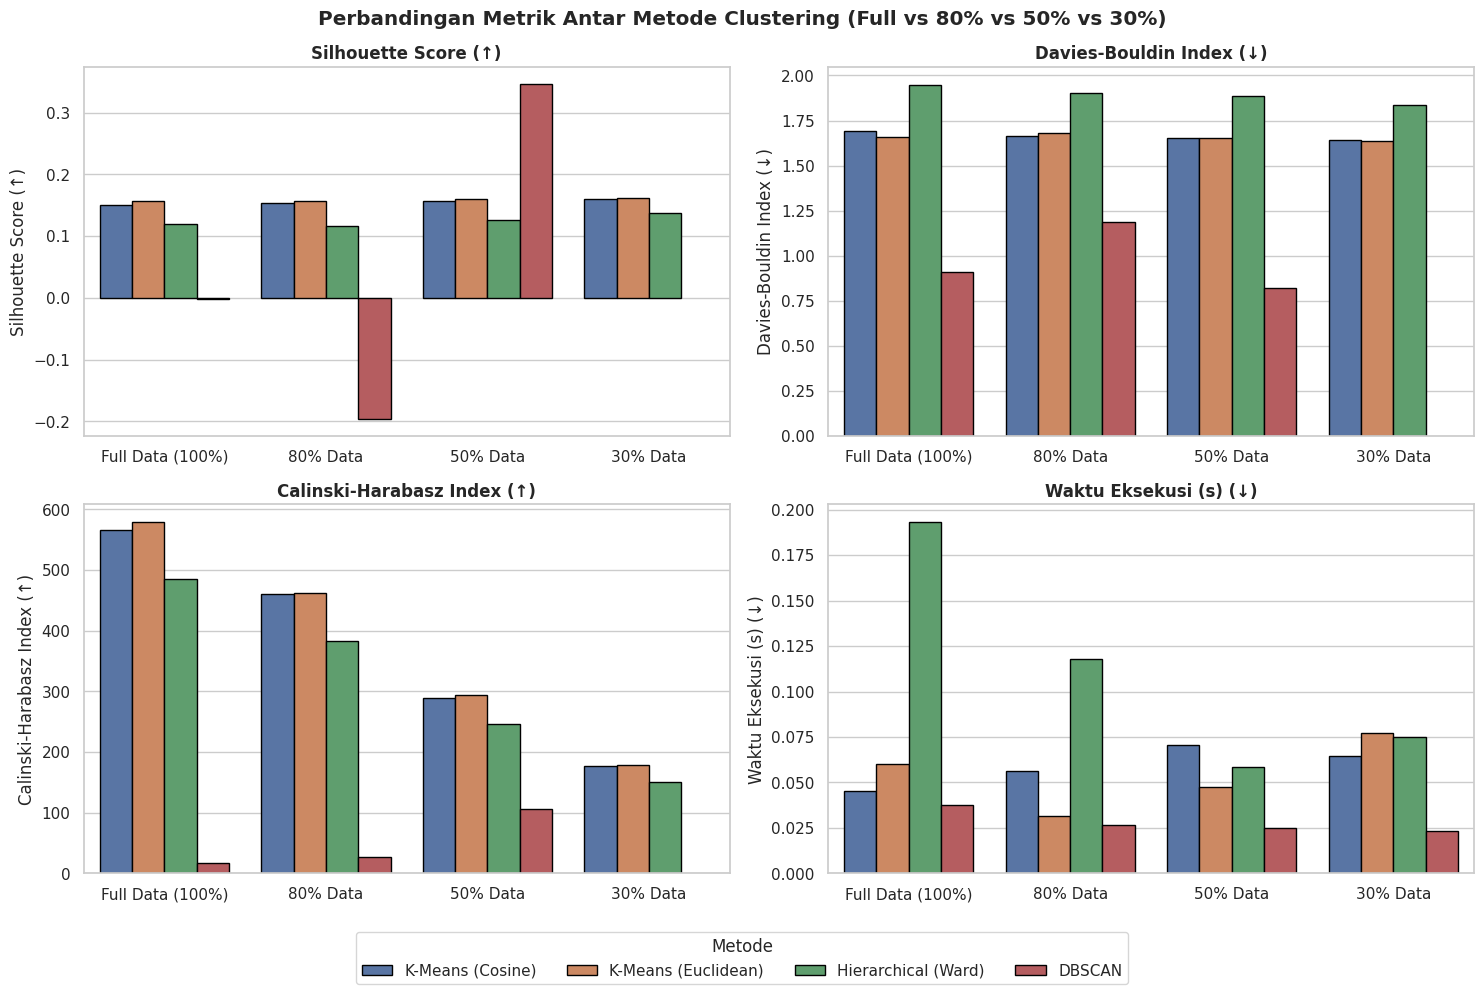

In [26]:
metrics = ['Silhouette Score (↑)', 'Davies-Bouldin Index (↓)', 'Calinski-Harabasz Index (↑)', 'Waktu Eksekusi (s) (↓)']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, col in zip(axes.ravel(), metrics):
    sns.barplot(data=eval_df, x='Skenario Data', y=col, hue='Metode', ax=ax, edgecolor='black')
    ax.set_title(col, fontweight='bold')
    ax.set_xlabel('')

handles, names = axes[0, 0].get_legend_handles_labels()
for ax in axes.ravel():
    ax.get_legend().remove()
fig.legend(handles, names, loc='lower center', ncol=len(names), title='Metode')

plt.suptitle('Perbandingan Metrik Antar Metode Clustering (Full vs 80% vs 50% vs 30%)', fontweight='bold')
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

# DBSCAN CORE SAMPLE/INSTANCE

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
RANDOM_STATE = 42

In [28]:
df = pd.read_csv('lettuce_dataset_updated.csv', encoding = "latin-1")

df.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


Jumlah baris: 3169 | Jumlah kolom: 9

Nama kolom: ['Plant_ID', 'Date', 'Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days', 'Temperature (F)', 'Humidity']

Tipe data:
 Plant_ID              int64
Date                 object
Temperature (°C)    float64
Humidity (%)          int64
TDS Value (ppm)       int64
pH Level            float64
Growth Days           int64
Temperature (F)     float64
Humidity            float64
dtype: object

10 data pertama:


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74
5,1,8/8/2023,32.3,77,478,6.8,6,90.14,0.77
6,1,8/9/2023,32.3,75,682,6.0,7,90.14,0.75
7,1,8/10/2023,22.7,63,576,6.3,8,72.86,0.63
8,1,8/11/2023,31.9,69,662,6.1,9,89.42,0.69
9,1,8/12/2023,30.2,59,607,6.2,10,86.36,0.59



10 data terakhir:


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
3159,70,9/8/2023,23.6,54,649,6.1,37,74.48,0.54
3160,70,9/9/2023,21.6,80,506,6.7,38,70.88,0.80
3161,70,9/10/2023,24.6,67,407,6.1,39,76.28,0.67
3162,70,9/11/2023,21.2,66,500,6.8,40,70.16,0.66
3163,70,9/12/2023,22.6,58,799,6.3,41,72.68,0.58
3164,70,9/13/2023,19.4,72,475,6.1,42,66.92,0.72
3165,70,9/14/2023,22.5,80,668,6.7,43,72.50,0.80
3166,70,9/15/2023,22.5,62,476,6.6,44,72.50,0.62
3167,70,9/16/2023,24.6,79,621,6.0,45,76.28,0.79
3168,70,9/17/2023,22.6,69,521,6.5,46,72.68,0.69



info():
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB

describe():
                   count        mean         std    min     25%     50%     75%    max
Plant_ID          3169.0   35.441780   20.243433    1.0   18.00   35.00   53.00   70.0
Temperature (°C)  3169.0   28.142222    4.670521   18.0   23.60   30.20   31.50   33.5
Humidity (%)      3169.0   64.

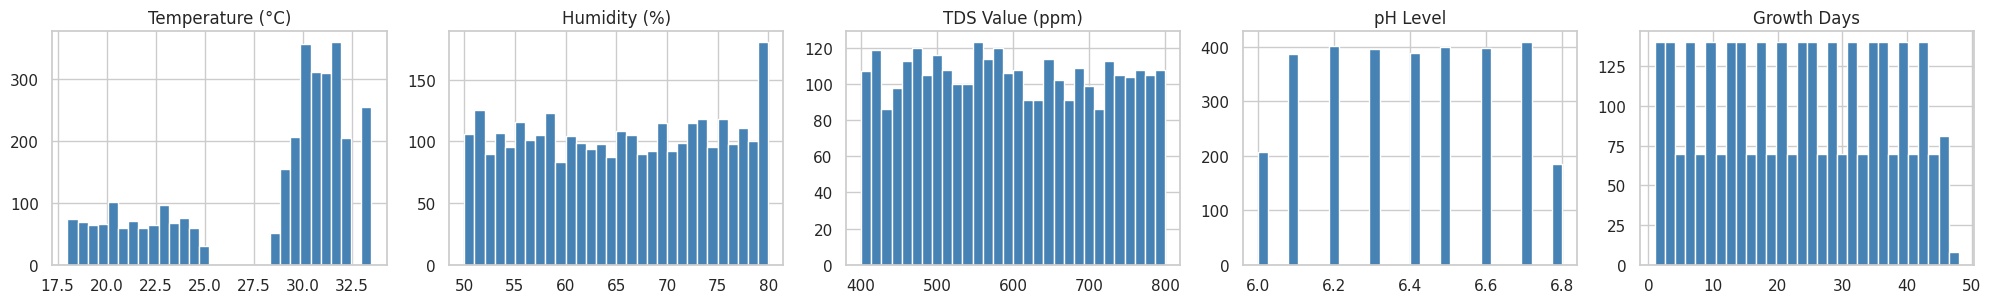


Korelasi antar fitur numerik:
                  Temperature (°C)  Humidity (%)  TDS Value (ppm)  pH Level  Growth Days
Temperature (°C)              1.00          0.03            -0.01      0.01        -0.07
Humidity (%)                  0.03          1.00            -0.01      0.02        -0.01
TDS Value (ppm)              -0.01         -0.01             1.00     -0.01        -0.02
pH Level                      0.01          0.02            -0.01      1.00         0.00
Growth Days                  -0.07         -0.01            -0.02      0.00         1.00


In [29]:
# CELL 3 — Eksplorasi Dataset
print("Jumlah baris:", df.shape[0], "| Jumlah kolom:", df.shape[1])
print("\nNama kolom:", list(df.columns))
print("\nTipe data:\n", df.dtypes)
print("\n10 data pertama:"); display(df.head(10))
print("\n10 data terakhir:"); display(df.tail(10))
print("\ninfo():"); df.info()
print("\ndescribe():"); print(df.describe().T)
print("\nMissing value per kolom:\n", df.isna().sum())
print("\nJumlah duplicated row:", df.duplicated().sum())
print("\nJumlah unique value per kolom:\n", df.nunique())
print("\nJumlah baris per Plant_ID:", df["Plant_ID"].value_counts().describe()[["min", "max"]].to_dict())

print("\nTemperature (F) == C*9/5+32 ? ->",
      np.allclose(df["Temperature (°C)"] * 9/5 + 32, df["Temperature (F)"]))
print("Humidity == Humidity(%)/100 ? ->",
      np.allclose(df["Humidity (%)"] / 100, df["Humidity"]))

num_cols = ["Temperature (°C)", "Humidity (%)", "TDS Value (ppm)", "pH Level", "Growth Days"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.2))
for ax, c in zip(axes, num_cols):
    ax.hist(df[c], bins=30, color="steelblue", edgecolor="white"); ax.set_title(c)
plt.tight_layout(); plt.show()
print("\nKorelasi antar fitur numerik:"); print(df[num_cols].corr().round(2))

In [30]:
# CELL 4 — Data Cleaning
n_awal = len(df)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
print("Missing value total :", int(df.isna().sum().sum()))
print("Duplikat (semua kolom):", df.duplicated().sum())

# Hapus KOLOM redundan (bukan baris)
df_clean = df.drop(columns=["Temperature (F)", "Humidity"])

# Outlier (IQR) hanya dicek, tidak dihapus
sensor_cols = ["Temperature (°C)", "Humidity (%)", "TDS Value (ppm)", "pH Level", "Growth Days"]
for c in sensor_cols:
    q1, q3 = df_clean[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = ((df_clean[c] < q1 - 1.5*iqr) | (df_clean[c] > q3 + 1.5*iqr)).sum()
    print(f"Outlier IQR {c:18s}: {n_out}")
print(f"Baris sebelum: {n_awal} | sesudah: {len(df_clean)} (tidak ada baris dihapus)")

Missing value total : 0
Duplikat (semua kolom): 0
Outlier IQR Temperature (°C)  : 0
Outlier IQR Humidity (%)      : 0
Outlier IQR TDS Value (ppm)   : 0
Outlier IQR pH Level          : 0
Outlier IQR Growth Days       : 0
Baris sebelum: 3169 | sesudah: 3169 (tidak ada baris dihapus)


In [31]:
# CELL 5 — Menentukan Fitur
features = ["Temperature (°C)", "Humidity (%)", "TDS Value (ppm)", "pH Level", "Growth Days"]
X = df_clean[features].copy()
print("Fitur clustering:", features)
print("Seluruhnya numerik:", all(pd.api.types.is_numeric_dtype(X[c]) for c in features))
print("Duplikat pada kombinasi 5 fitur:", X.duplicated().sum(), "(dipertahankan: pengukuran berbeda)")

Fitur clustering: ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
Seluruhnya numerik: True
Duplikat pada kombinasi 5 fitur: 1 (dipertahankan: pengukuran berbeda)


In [32]:
# CELL 6 — Membagi Dataset
df_full = X.copy()
df_80   = X.sample(frac=0.8, random_state=RANDOM_STATE)
df_50   = X.sample(frac=0.5, random_state=RANDOM_STATE)
df_30   = X.sample(frac=0.3, random_state=RANDOM_STATE)

subsets = {"100%": df_full, "80%": df_80, "50%": df_50, "30%": df_30}
print(f"Full Data : {len(df_full)} rows")
print(f"80% Data  : {len(df_80)} rows")
print(f"50% Data  : {len(df_50)} rows")
print(f"30% Data  : {len(df_30)} rows")

Full Data : 3169 rows
80% Data  : 2535 rows
50% Data  : 1584 rows
30% Data  : 951 rows


In [33]:
# CELL 7 — Scaling: StandardScaler per proporsi data (sama dengan metode lain)
scaled = {name: pd.DataFrame(StandardScaler().fit_transform(d), index=d.index, columns=features)
          for name, d in subsets.items()}
print("Mean (full):", scaled["100%"].mean().round(3).to_dict())


Mean (full): {'Temperature (°C)': -0.0, 'Humidity (%)': -0.0, 'TDS Value (ppm)': -0.0, 'pH Level': 0.0, 'Growth Days': 0.0}


min_samples = 10
eps (ditetapkan) = 0.64


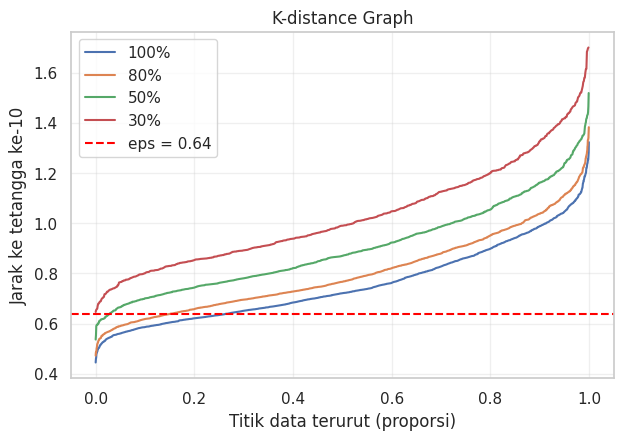

In [34]:
# CELL 8 — Parameter DBSCAN
def k_distances(Xs, k):
    nn = NearestNeighbors(n_neighbors=k).fit(Xs)
    d, _ = nn.kneighbors(Xs)
    return np.sort(d[:, -1])

def find_knee(kd):
    x = np.arange(len(kd)); y = kd
    p1, p2 = np.array([x[0], y[0]]), np.array([x[-1], y[-1]])
    v = (p2 - p1) / np.linalg.norm(p2 - p1)
    pts = np.c_[x, y] - p1
    dist = np.abs(pts[:, 0]*v[1] - pts[:, 1]*v[0])
    return int(np.argmax(dist))

MIN_SAMPLES = 10
kd_all = {name: k_distances(Xs.values, MIN_SAMPLES) for name, Xs in scaled.items()}
EPS = 0.64  # ditetapkan
print(f"min_samples = {MIN_SAMPLES}")
print(f"eps (ditetapkan) = {EPS}")

plt.figure(figsize=(7, 4.5))
for name, kd in kd_all.items():
    plt.plot(np.arange(len(kd)) / len(kd), kd, label=name)
plt.axhline(EPS, color="red", ls="--", label=f"eps = {EPS}")
plt.xlabel("Titik data terurut (proporsi)"); plt.ylabel(f"Jarak ke tetangga ke-{MIN_SAMPLES}")
plt.title("K-distance Graph"); plt.legend(); plt.grid(alpha=.3); plt.show()

In [35]:
import time
# CELL 9–12 — DBSCAN pada 100%, 80%, 50%, 30%
def run_dbscan(Xs, eps, min_samples):
    return DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xs)

def cluster_summary(labels):
    unique, counts = np.unique(labels, return_counts=True)
    sizes = {int(u): int(c) for u, c in zip(unique, counts) if u != -1}
    n_noise = int((labels == -1).sum())
    return len(sizes), n_noise, 100 * n_noise / len(labels), sizes

results, labels_dict, times_db = [], {}, {}
for name in ["100%", "80%", "50%", "30%"]:
    t0 = time.perf_counter()
    labels = run_dbscan(scaled[name].values, EPS, MIN_SAMPLES)
    times_db[name] = time.perf_counter() - t0
    labels_dict[name] = pd.Series(labels, index=scaled[name].index)
    n_cl, n_noise, pct_noise, sizes = cluster_summary(labels)
    print(f"\n=== DBSCAN {name} (n={len(labels)}) ===")
    print(f"Jumlah cluster : {n_cl}")
    print(f"Jumlah noise   : {n_noise} ({pct_noise:.2f}%)")
    print(f"Anggota cluster: {sizes}")


=== DBSCAN 100% (n=3169) ===
Jumlah cluster : 4
Jumlah noise   : 1358 (42.85%)
Anggota cluster: {0: 1782, 1: 9, 2: 10, 3: 10}

=== DBSCAN 80% (n=2535) ===
Jumlah cluster : 11
Jumlah noise   : 1434 (56.57%)
Anggota cluster: {0: 930, 1: 39, 2: 24, 3: 19, 4: 19, 5: 30, 6: 8, 7: 9, 8: 8, 9: 11, 10: 4}

=== DBSCAN 50% (n=1584) ===
Jumlah cluster : 14
Jumlah noise   : 1339 (84.53%)
Anggota cluster: {0: 16, 1: 24, 2: 31, 3: 38, 4: 12, 5: 44, 6: 10, 7: 13, 8: 13, 9: 8, 10: 10, 11: 9, 12: 7, 13: 10}

=== DBSCAN 30% (n=951) ===
Jumlah cluster : 0
Jumlah noise   : 951 (100.00%)
Anggota cluster: {}


In [36]:
# CELL 13 — Evaluasi
from sklearn.metrics import calinski_harabasz_score
def evaluate_clustering(Xs, labels):
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    out = {"Jumlah Cluster": n_cl, "Jumlah Noise": int((~mask).sum()),
           "Silhouette Score": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    if n_cl >= 2 and mask.sum() > n_cl:
        out["Silhouette Score"] = round(silhouette_score(Xs[mask], labels[mask]), 4)
        out["Davies-Bouldin"] = round(davies_bouldin_score(Xs[mask], labels[mask]), 4)
        out["Calinski-Harabasz"] = round(calinski_harabasz_score(Xs[mask], labels[mask]), 2)
    return out

rows = []
for name in ["100%", "80%", "50%", "30%"]:
    ev = evaluate_clustering(scaled[name].values, labels_dict[name].values)
    idx = labels_dict[name].index
    ari = adjusted_rand_score(labels_dict["100%"].loc[idx], labels_dict[name])
    rows.append({"Proporsi Data": name, "Jumlah Data": len(idx), "min_samples": MIN_SAMPLES, "eps": EPS,
                 **ev, "Waktu Eksekusi (s)": round(times_db[name], 5), "ARI vs Full": round(ari, 4)})


Explained variance ratio: [0.217 0.206] | total: 0.423


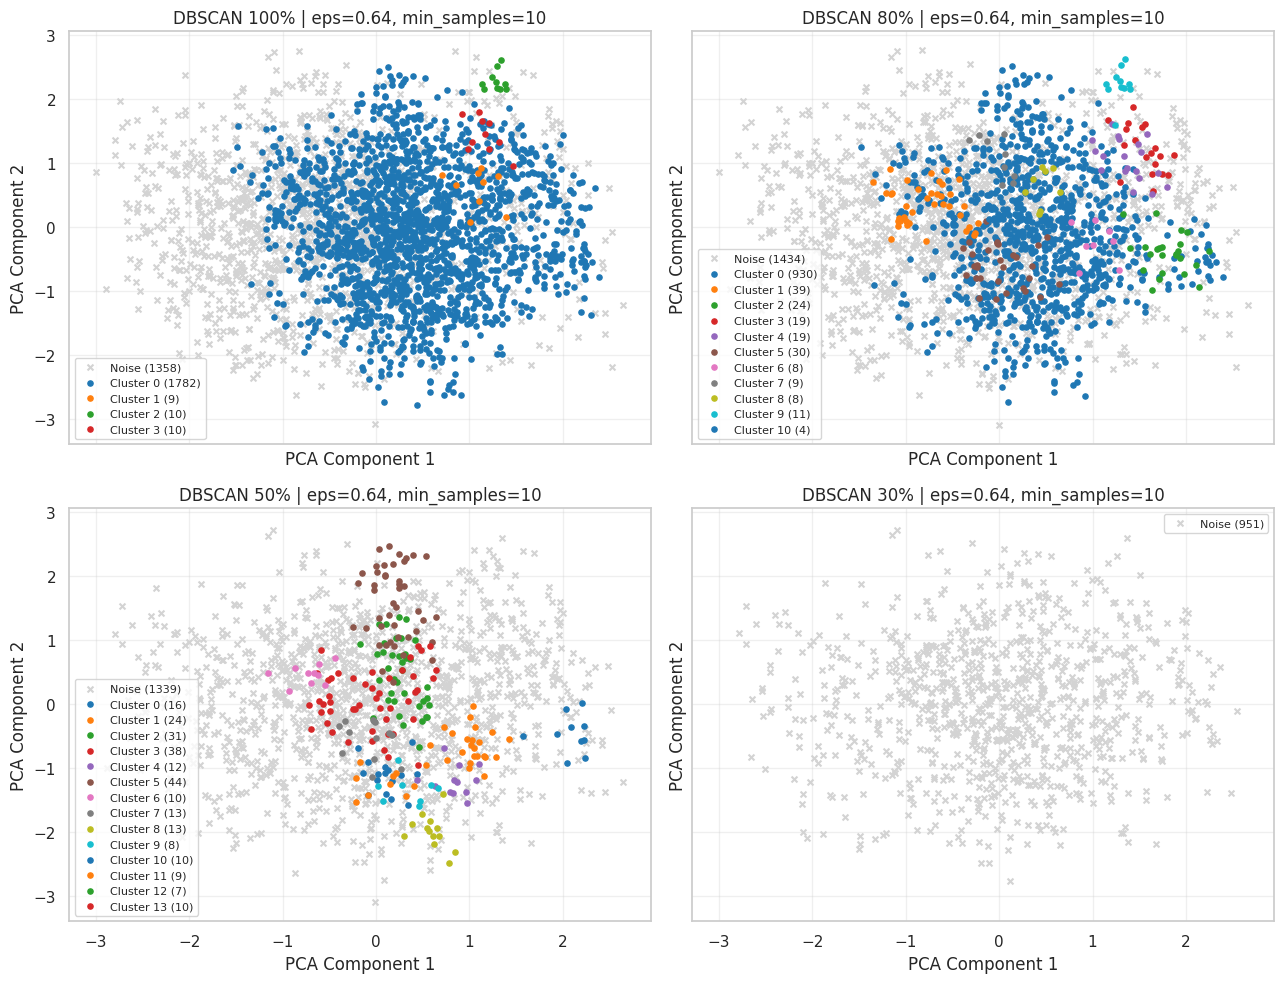

In [37]:
# CELL 14 — Visualisasi PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(scaled["100%"])
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
palette = plt.cm.tab10.colors
for ax, name in zip(axes.ravel(), ["100%", "80%", "50%", "30%"]):
    P = pca.transform(scaled[name]); lab = labels_dict[name].values
    noise = lab == -1
    ax.scatter(P[noise, 0], P[noise, 1], c="lightgray", marker="x", s=18, label=f"Noise ({noise.sum()})")
    for c in sorted(set(lab) - {-1}):
        m = lab == c
        ax.scatter(P[m, 0], P[m, 1], s=14, color=palette[c % 10], label=f"Cluster {c} ({m.sum()})")
    ax.set_title(f"DBSCAN {name} | eps={EPS}, min_samples={MIN_SAMPLES}")
    ax.set_xlabel("PCA Component 1"); ax.set_ylabel("PCA Component 2")
    ax.legend(fontsize=8, loc="best"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [38]:
# CELL 15 — Tabel Perbandingan DBSCAN (min_samples=10, eps=0.64)
comparison = pd.DataFrame(rows).set_index("Proporsi Data")
display(comparison)


,Jumlah Data,min_samples,eps,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s),ARI vs Full
Proporsi Data,,,,,,,,,,
100%,3169,10,0.64,4,1358,-0.0019,0.9083,17.10,0.03877,1.0000
80%,2535,10,0.64,11,1434,-0.1966,1.1866,27.09,0.02894,0.4279
50%,1584,10,0.64,14,1339,0.3479,0.8181,106.53,0.01294,-0.0248
30%,951,10,0.64,0,951,NaN,NaN,NaN,0.00623,0.0000


# DBSCAN NON-SAMPLE/BORDER INSTANCE

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Membaca dataset
df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')
df.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [40]:
import pandas as pd
print("Ukuran Dataset:", df.shape)
print("\nNama Kolom:", df.columns.tolist())
print("\nInformasi Dataset:")
df.info()
print("\nJumlah Missing Value:")
print(df.isnull().sum())

Ukuran Dataset: (3169, 9)

Nama Kolom: ['Plant_ID', 'Date', 'Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days', 'Temperature (F)', 'Humidity']

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3169 entries, 0 to 3168
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Plant_ID          3169 non-null   int64  
 1   Date              3169 non-null   object 
 2   Temperature (°C)  3169 non-null   float64
 3   Humidity (%)      3169 non-null   int64  
 4   TDS Value (ppm)   3169 non-null   int64  
 5   pH Level          3169 non-null   float64
 6   Growth Days       3169 non-null   int64  
 7   Temperature (F)   3169 non-null   float64
 8   Humidity          3169 non-null   float64
dtypes: float64(4), int64(4), object(1)
memory usage: 222.9+ KB

Jumlah Missing Value:
Plant_ID            0
Date                0
Temperature (°C)    0
Humidity (%)        0
TDS Value

In [41]:
features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
X_raw = df[features].copy()
print("Fitur yang digunakan untuk clustering:")
display(X_raw.head())

Fitur yang digunakan untuk clustering:


,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days
0,33.4,53,582,6.4,1
1,33.5,53,451,6.1,2
2,33.4,59,678,6.4,3
3,33.4,68,420,6.4,4
4,33.4,74,637,6.5,5


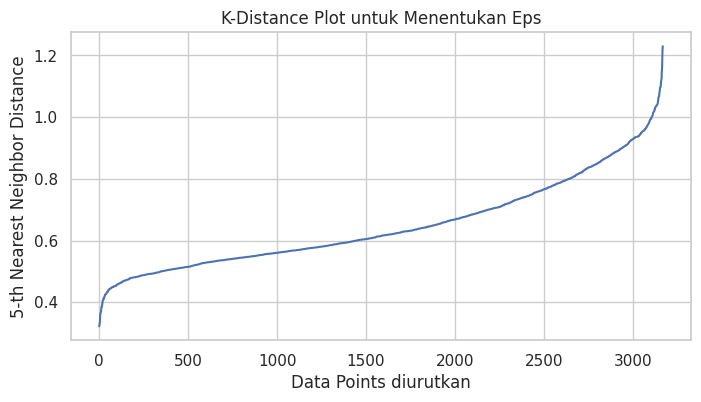

In [42]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Standardisasi fitur
scaler = StandardScaler()
X_scaled_full = scaler.fit_transform(X_raw)

# Menggunakan min_samples = 6
min_samples_val = 6

neighbors = NearestNeighbors(n_neighbors=min_samples_val)
neighbors_fit = neighbors.fit(X_scaled_full)
distances, indices = neighbors_fit.kneighbors(X_scaled_full)

# Urutkan jarak terdekat
distances = np.sort(distances[:, min_samples_val-1], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances)
plt.title("K-Distance Plot untuk Menentukan Eps")
plt.xlabel("Data Points diurutkan")
plt.ylabel(f"{min_samples_val-1}-th Nearest Neighbor Distance")
plt.grid(True)
plt.show()

In [43]:
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

eps_val = 0.64
min_samples_val = 10

def analyze_dbscan(data_fraction, fraction_name, full_df, features, eps, min_samples):
    # Sampling
    if data_fraction < 1.0:
        df_sub = full_df.sample(frac=data_fraction, random_state=42).copy()
    else:
        df_sub = full_df.copy()

    # Preprocessing
    X_sub = df_sub[features]
    scaler_sub = StandardScaler()
    X_scaled = scaler_sub.fit_transform(X_sub)

    # DBSCAN Fit
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_scaled)
    labels = db.labels_

    # Cari Core Samples indices
    core_samples_mask = np.zeros_like(labels, dtype=bool)
    core_samples_mask[db.core_sample_indices_] = True

    # Klasifikasikan setiap baris
    type_labels = []
    for idx in range(len(labels)):
        if core_samples_mask[idx]:
            type_labels.append('Core')
        elif labels[idx] != -1:
            type_labels.append('Border')
        else:
            type_labels.append('Noise')

    df_sub['DBSCAN_Type'] = type_labels
    df_sub['Cluster_Label'] = labels

    # Hitung jumlah masing-masing tipe
    num_core = sum(df_sub['DBSCAN_Type'] == 'Core')
    num_border = sum(df_sub['DBSCAN_Type'] == 'Border')
    num_noise = sum(df_sub['DBSCAN_Type'] == 'Noise')
    pct_border = (num_border / len(df_sub)) * 100

    summary = {
        'Dataset': fraction_name,
        'Jumlah Data': len(df_sub),
        'Core Sample': num_core,
        'Border Instance': num_border,
        'Noise': num_noise,
        '% Border': f"{pct_border:.2f}%"
    }

    return df_sub, X_scaled, summary

# Jalankan keempat skenario
results = {}
summaries = []

for frac, name in zip([1.0, 0.8, 0.5, 0.3], ['100% (Full)', '80% Data', '50% Data', '30% Data']):
    df_res, X_sc, sum_res = analyze_dbscan(frac, name, df, features, eps_val, min_samples_val)
    results[name] = (df_res, X_sc)
    summaries.append(sum_res)

In [44]:
import pandas as pd
df_summary = pd.DataFrame(summaries)
display(df_summary)

,Dataset,Jumlah Data,Core Sample,Border Instance,Noise,% Border
0,100% (Full),3169,854,957,1358,30.20%
1,80% Data,2535,392,709,1434,27.97%
2,50% Data,1584,46,199,1339,12.56%
3,30% Data,951,0,0,951,0.00%


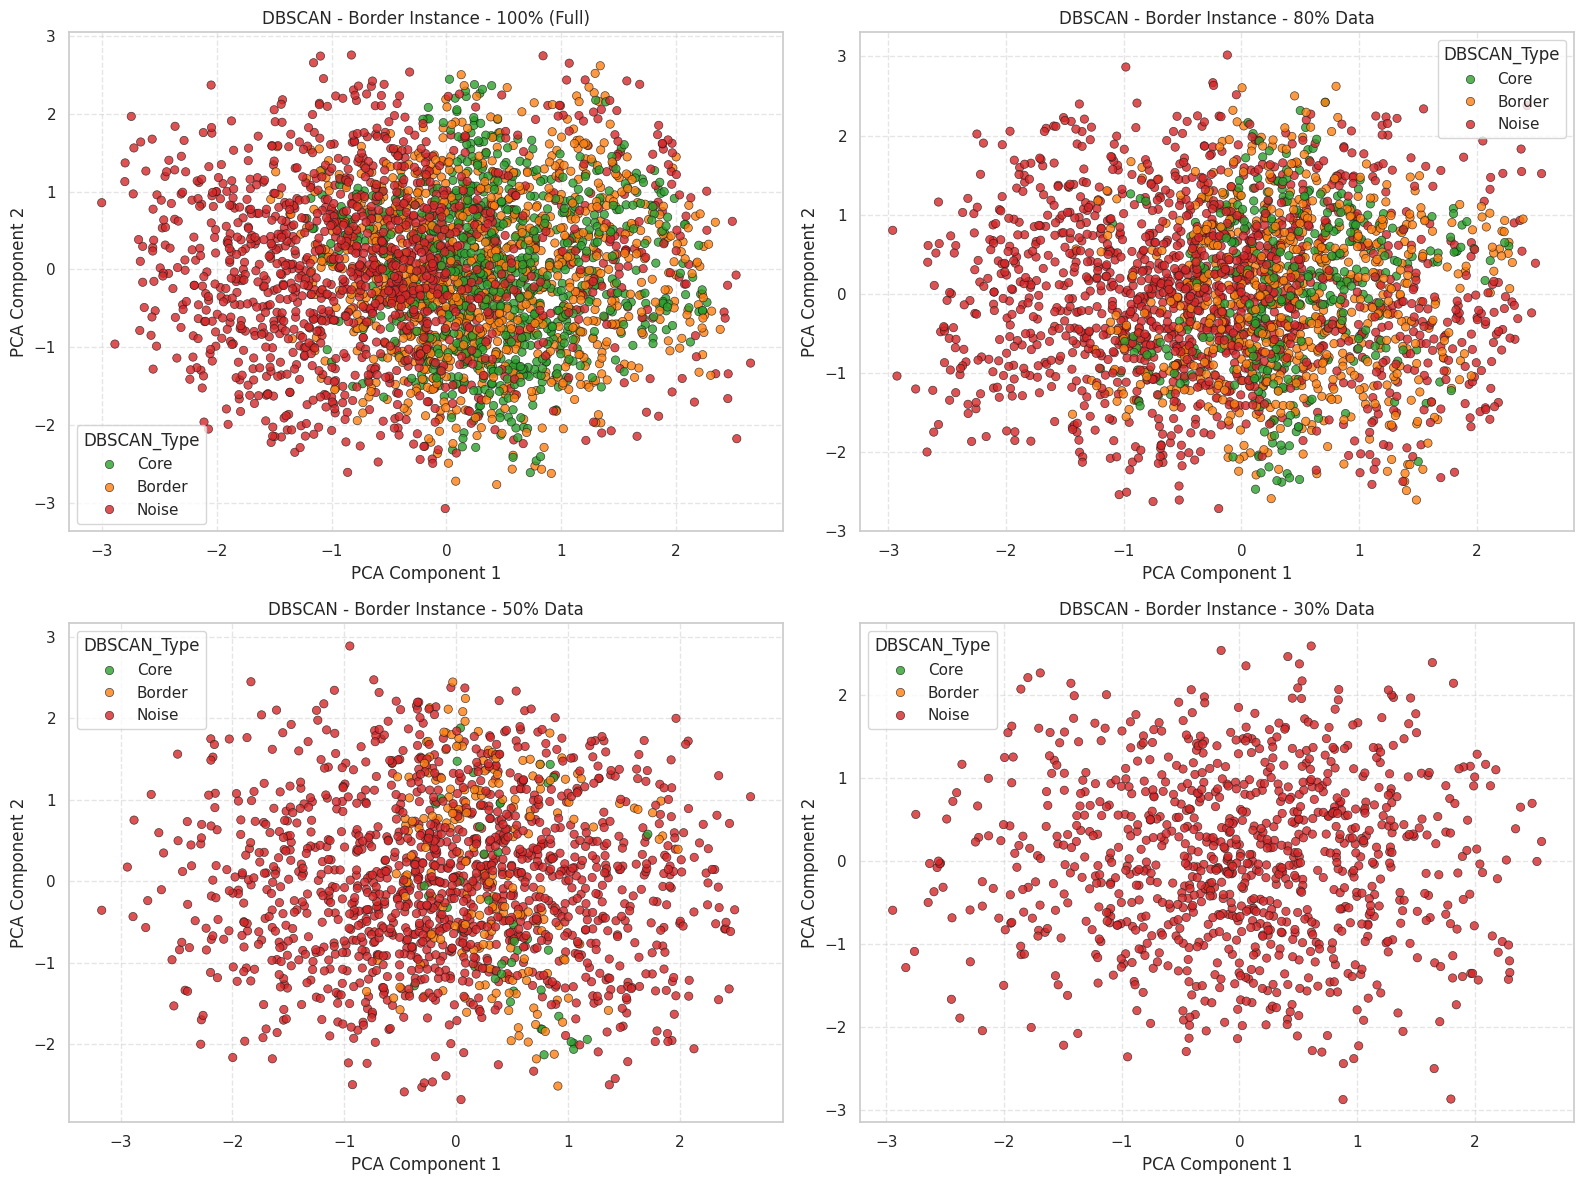

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, name in enumerate(['100% (Full)', '80% Data', '50% Data', '30% Data']):
    df_res, X_sc = results[name]

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_sc)

    df_plot = df_res.copy()
    df_plot['PCA1'] = X_pca[:, 0]
    df_plot['PCA2'] = X_pca[:, 1]

    sns.scatterplot(
        x='PCA1', y='PCA2', hue='DBSCAN_Type',
        hue_order=['Core', 'Border', 'Noise'],
        palette={'Core': '#2ca02c', 'Border': '#ff7f0e', 'Noise': '#d62728'},
        data=df_plot, ax=axes[i], alpha=0.8, edgecolor='k'
    )
    axes[i].set_title(f"DBSCAN - Border Instance - {name}")
    axes[i].set_xlabel("PCA Component 1")
    axes[i].set_ylabel("PCA Component 2")
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [46]:
for name in ['100% (Full)', '80% Data', '50% Data', '30% Data']:
    df_res, _ = results[name]
    border_df = df_res[df_res['DBSCAN_Type'] == 'Border']
    print(f"=== Border Instance - {name} (Total: {len(border_df)}) ===")
    display(border_df.head(5))

=== Border Instance - 100% (Full) (Total: 957) ===


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity,DBSCAN_Type,Cluster_Label
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53,Border,0
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53,Border,1
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59,Border,0
8,1,8/11/2023,31.9,69,662,6.1,9,89.42,0.69,Border,0
10,1,8/13/2023,30.1,77,670,6.5,11,86.18,0.77,Border,0


=== Border Instance - 80% Data (Total: 709) ===


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity,DBSCAN_Type,Cluster_Label
1866,42,8/12/2023,30.2,62,751,6.5,10,86.36,0.62,Border,0
1412,32,8/8/2023,32.3,66,494,6.4,6,90.14,0.66,Border,0
1362,31,8/3/2023,33.4,77,477,6.3,1,92.12,0.77,Border,0
1236,28,8/12/2023,30.2,53,455,6.2,10,86.36,0.53,Border,0
2032,45,9/12/2023,31.2,51,571,6.3,41,88.16,0.51,Border,1


=== Border Instance - 50% Data (Total: 199) ===


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity,DBSCAN_Type,Cluster_Label
1362,31,8/3/2023,33.4,77,477,6.3,1,92.12,0.77,Border,10
1251,28,8/27/2023,30.1,73,411,6.3,25,86.18,0.73,Border,4
1510,34,8/16/2023,29.8,55,794,6.3,14,85.64,0.55,Border,5
1436,32,9/1/2023,31.7,72,586,6.7,30,89.06,0.72,Border,9
1340,30,8/26/2023,31.4,58,593,6.4,24,88.52,0.58,Border,2


=== Border Instance - 30% Data (Total: 0) ===


,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity,DBSCAN_Type,Cluster_Label


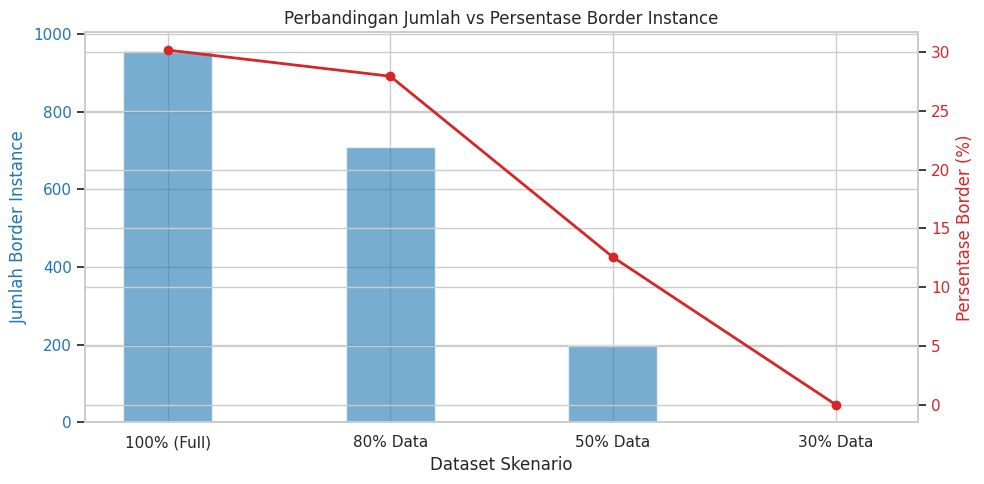

In [47]:
import matplotlib.pyplot as plt

df_summary['% Border_float'] = df_summary['% Border'].str.rstrip('%').astype(float)

fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Dataset Skenario')
ax1.set_ylabel('Jumlah Border Instance', color=color)
ax1.bar(df_summary['Dataset'], df_summary['Border Instance'], color=color, alpha=0.6, width=0.4, label='Jumlah Border')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Persentase Border (%)', color=color)
ax2.plot(df_summary['Dataset'], df_summary['% Border_float'], color=color, marker='o', linewidth=2, label='Persentase Border')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Perbandingan Jumlah vs Persentase Border Instance')
fig.tight_layout()
plt.show()

# DBSCAN OUTLIER/NOISER/ANOMALI

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('lettuce_dataset_updated.csv', encoding = "latin1")

df.head()

,Plant_ID,Date,Temperature (°C),Humidity (%),TDS Value (ppm),pH Level,Growth Days,Temperature (F),Humidity
0,1,8/3/2023,33.4,53,582,6.4,1,92.12,0.53
1,1,8/4/2023,33.5,53,451,6.1,2,92.30,0.53
2,1,8/5/2023,33.4,59,678,6.4,3,92.12,0.59
3,1,8/6/2023,33.4,68,420,6.4,4,92.12,0.68
4,1,8/7/2023,33.4,74,637,6.5,5,92.12,0.74


In [49]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Definisikan Fitur & Normalisasi Data Full (100%)
dbscan_features = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
X_scaled_full = StandardScaler().fit_transform(df[dbscan_features])

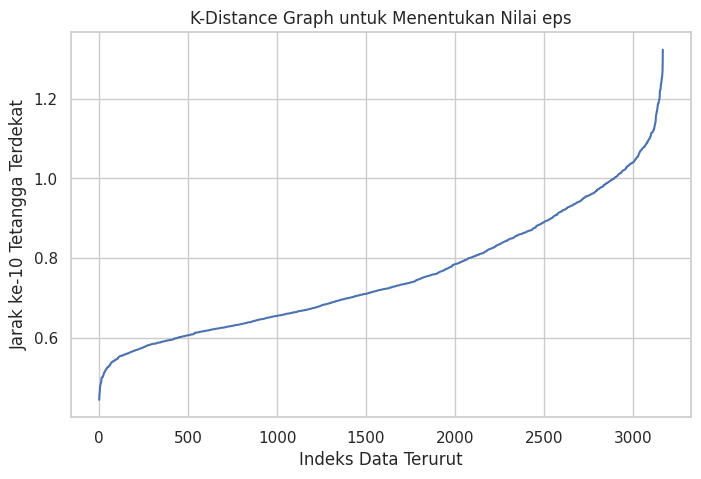

In [50]:
# 2. K-Distance Graph
min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled_full)
distances, _ = nn.kneighbors(X_scaled_full)
k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel('Indeks Data Terurut')
plt.ylabel(f'Jarak ke-{min_samples} Tetangga Terdekat')
plt.title('K-Distance Graph untuk Menentukan Nilai eps')
plt.grid(True)
plt.show()

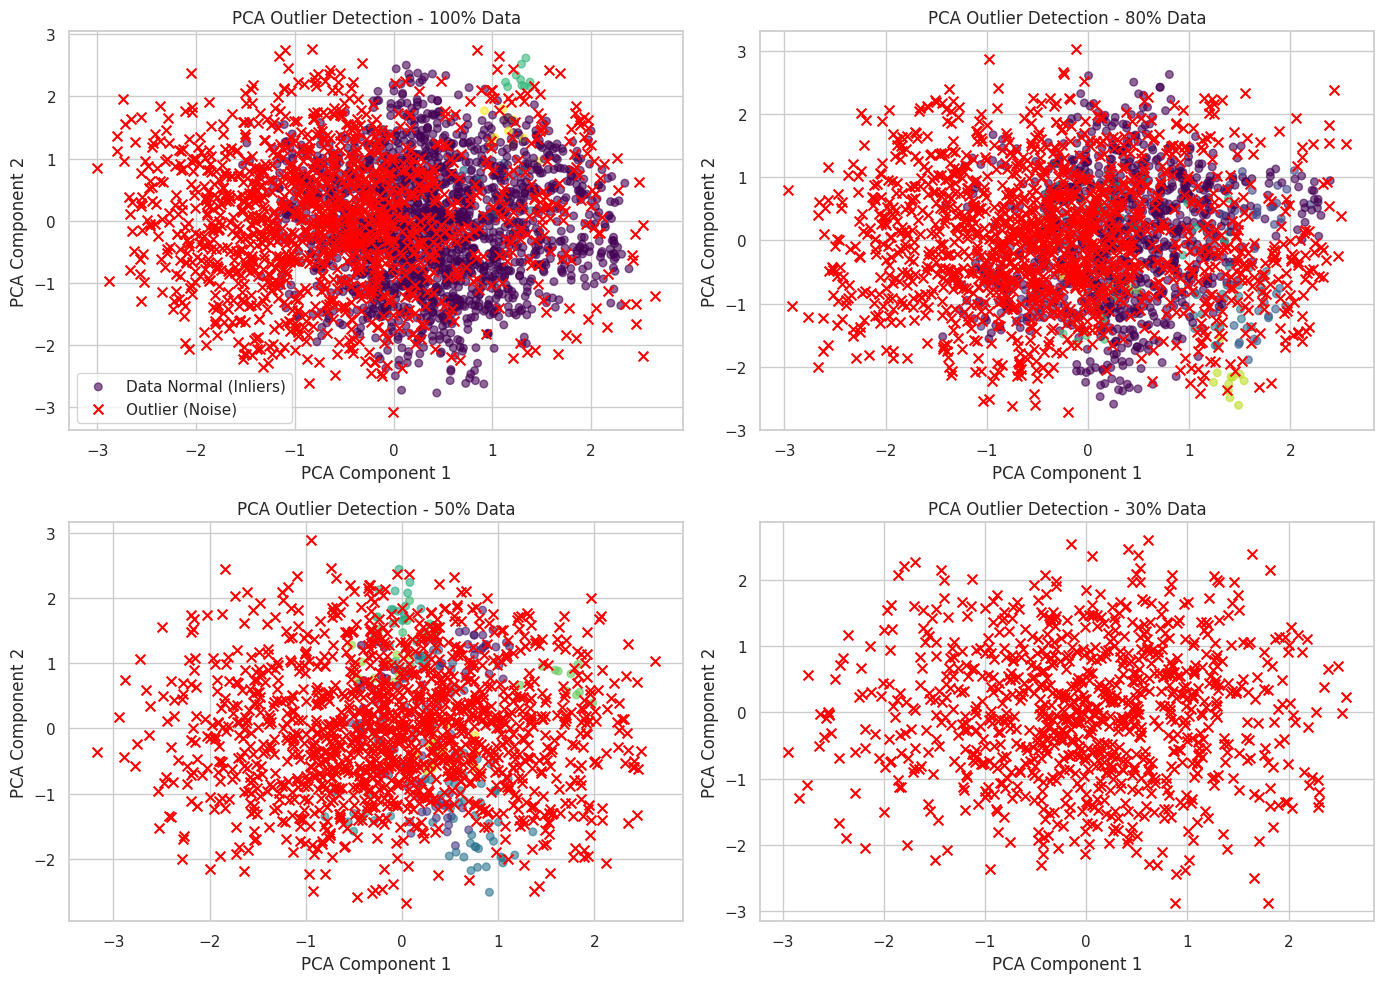

In [51]:
# 3. Evaluasi DBSCAN, Simpan Hasil Tabel, & Visualisasi Outlier PCA
percentages = [1.0, 0.8, 0.5, 0.3]
eps_val = 0.64
tabel_hasil = []
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, p in enumerate(percentages):
    # Sampling data sesuai proporsi
    df_sub = df if p == 1.0 else df.sample(frac=p, random_state=42).copy()
    X_sub_scaled = StandardScaler().fit_transform(df_sub[dbscan_features])

    # Fit DBSCAN & Prediksi Cluster
    dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
    clusters = dbscan.fit_predict(X_sub_scaled)

    # Hitung Titik Bising
    n_noise = (clusters == -1).sum()
    total = len(df_sub)
    persentase_noise = (n_noise / total) * 100

    # Simpan hasil iterasi saat ini ke dalam list tabel_hasil
    tabel_hasil.append({
        'Proporsi Data': f"{int(p*100)}%",
        'Total Data': total,
        'Nilai eps': eps_val,
        'Titik Bising (Noise)': n_noise,
        'Persentase Noise (%)': f"{persentase_noise:.2f}%"
    })

    # Visualisasi PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_sub_scaled)

    outliers = clusters == -1
    inliers = clusters != -1

    axes[idx].scatter(X_pca[inliers, 0], X_pca[inliers, 1], c=clusters[inliers], cmap='viridis', s=30, alpha=0.6, label='Data Normal (Inliers)')
    axes[idx].scatter(X_pca[outliers, 0], X_pca[outliers, 1], color='red', marker='x', s=50, label='Outlier (Noise)')

    axes[idx].set_title(f'PCA Outlier Detection - {int(p*100)}% Data')
    axes[idx].set_xlabel('PCA Component 1')
    axes[idx].set_ylabel('PCA Component 2')

    if idx == 0:
        axes[idx].legend()

# Tampilkan scatter plot
plt.tight_layout()
plt.show()

In [52]:
print("\nTabel Perbandingan Hasil Deteksi Outlier (DBSCAN)")
df_hasil_dbscan = pd.DataFrame(tabel_hasil)

display(df_hasil_dbscan)


Tabel Perbandingan Hasil Deteksi Outlier (DBSCAN)


,Proporsi Data,Total Data,Nilai eps,Titik Bising (Noise),Persentase Noise (%)
0,100%,3169,0.64,1358,42.85%
1,80%,2535,0.64,1434,56.57%
2,50%,1584,0.64,1339,84.53%
3,30%,951,0.64,951,100.00%


# Hierarchical Clustering (Agglomerative) + Perbandingan Final

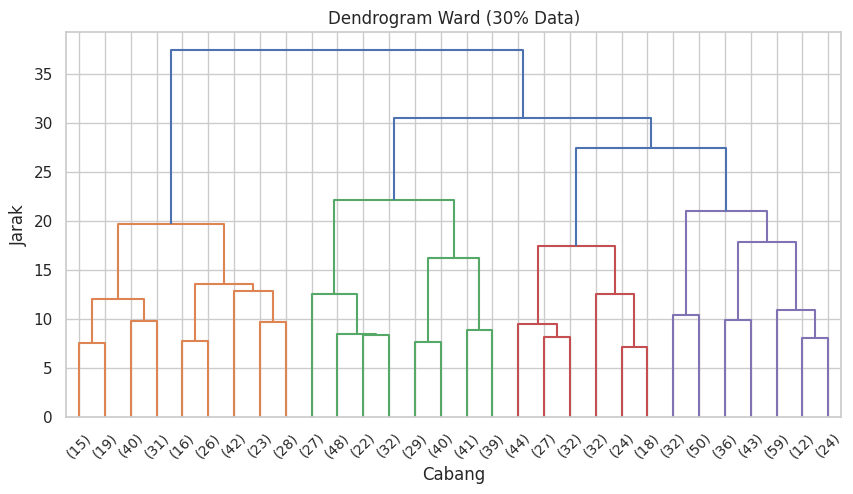

,Linkage,Cluster,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,ward,4,0.1193,1.9496,484.75,0.1977
1,complete,4,0.0788,2.2062,322.48,0.1910
2,average,4,0.1229,1.9458,323.16,0.1724
3,single,4,0.0940,1.3317,231.90,0.0533


In [53]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')
FEATURES = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
X_full = StandardScaler().fit_transform(df[FEATURES])

# Dendrogram (30% data agar terbaca; dipotong ke 30 cabang terakhir)
X_d = StandardScaler().fit_transform(df.sample(frac=0.3, random_state=42)[FEATURES])
plt.figure(figsize=(10, 5))
dendrogram(linkage(X_d, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram Ward (30% Data)'); plt.xlabel('Cabang'); plt.ylabel('Jarak'); plt.show()

# Bandingkan jenis linkage pada Full Data (k=4)
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    t0 = time.perf_counter()
    lab = AgglomerativeClustering(n_clusters=4, linkage=link).fit_predict(X_full)
    t = time.perf_counter() - t0
    rows.append({'Linkage': link, 'Cluster': 4, 'Silhouette Score': round(silhouette_score(X_full, lab), 4),
                 'Davies-Bouldin': round(davies_bouldin_score(X_full, lab), 4),
                 'Calinski-Harabasz': round(calinski_harabasz_score(X_full, lab), 2),
                 'Waktu Eksekusi (s)': round(t, 4)})
pd.DataFrame(rows)


# Tabel Gabungan: Semua Metode x Semua Proporsi Data

In [55]:
import time, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
try:
    from sklearn.cluster import HDBSCAN   # sklearn >= 1.3
except ImportError:
    HDBSCAN = None

df = pd.read_csv('lettuce_dataset_updated.csv', encoding='latin1')
FEATURES = ['Temperature (°C)', 'Humidity (%)', 'TDS Value (ppm)', 'pH Level', 'Growth Days']
FRACS = {"Full Data (100%)": 1.0, "80% Data": 0.8, "50% Data": 0.5, "30% Data": 0.3}
K, MS, EPS = 4, 10, 0.64

# Preprocessing seragam: StandardScaler per proporsi data
splits = {n: StandardScaler().fit_transform((df if f == 1 else df.sample(frac=f, random_state=42))[FEATURES])
          for n, f in FRACS.items()}

# (pembuat model, kolom Cluster, kolom min_samples, kolom eps)
METHODS = {
    "K-Means (Euclidean)": (lambda: CustomKMeans(n_clusters=K, metric='euclidean'), K, '-', '-'),
    "K-Medians (Manhattan)": (lambda: CustomKMedians(n_clusters=K, metric='cityblock'), K, '-', '-'),
    "K-Means (Cosine)": (lambda: KMeansCosine(n_clusters=K), K, '-', '-'),
    "Hierarchical (Ward)": (lambda: AgglomerativeClustering(n_clusters=K, linkage='ward'), K, '-', '-'),
    "DBSCAN": (lambda: DBSCAN(eps=EPS, min_samples=MS), '-', MS, EPS),
}
if HDBSCAN is not None:
    METHODS["HDBSCAN"] = (lambda: HDBSCAN(min_cluster_size=MS, min_samples=MS), '-', MS, '-')

def evaluate(X, lab):
    m = lab != -1   # noise diabaikan
    if len(set(lab[m])) < 2:
        return [np.nan] * 3
    return [silhouette_score(X[m], lab[m]), davies_bouldin_score(X[m], lab[m]), calinski_harabasz_score(X[m], lab[m])]

rows = []
for sname, X in splits.items():
    for mname, (make, k, ms, eps) in METHODS.items():
        model = make()
        t0 = time.perf_counter(); model.fit(X); t = time.perf_counter() - t0
        lab = model.labels_ if hasattr(model, 'labels_') else model.labels
        sil, db, ch = evaluate(X, np.asarray(lab))
        rows.append({'Proporsi Data': sname, 'Metode': mname, 'Cluster': k, 'min_samples': ms, 'eps': eps,
                     'Silhouette Score': round(sil, 4), 'Davies-Bouldin': round(db, 4),
                     'Calinski-Harabasz': round(ch, 2), 'Waktu Eksekusi (s)': round(t, 5)})

final_df = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
display(final_df)

# Rata-rata per metode
display(final_df.groupby('Metode')[['Silhouette Score', 'Davies-Bouldin', 'Calinski-Harabasz', 'Waktu Eksekusi (s)']].mean().round(4))


,Proporsi Data,Metode,Cluster,min_samples,eps,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
0,Full Data (100%),K-Means (Euclidean),4,-,-,0.1547,1.6698,574.59,0.00990
1,Full Data (100%),K-Medians (Manhattan),4,-,-,0.1430,1.7580,518.45,0.03366
2,Full Data (100%),K-Means (Cosine),4,-,-,0.1501,1.6919,565.48,0.08117
3,Full Data (100%),Hierarchical (Ward),4,-,-,0.1193,1.9496,484.75,0.44741
4,Full Data (100%),DBSCAN,-,10,0.64,-0.0019,0.9083,17.10,0.07450
5,Full Data (100%),HDBSCAN,-,10,-,0.2044,1.8457,507.54,0.24054
6,80% Data,K-Means (Euclidean),4,-,-,0.1493,1.7912,393.52,0.06518
7,80% Data,K-Medians (Manhattan),4,-,-,0.1331,1.8346,400.66,0.01904
8,80% Data,K-Means (Cosine),4,-,-,0.1530,1.6799,457.37,0.06066
9,80% Data,Hierarchical (Ward),4,-,-,0.1159,1.9020,382.86,0.29355


,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Waktu Eksekusi (s)
Metode,,,,
DBSCAN,0.0498,0.9710,50.2400,0.0352
HDBSCAN,0.2010,1.7499,283.2150,0.1080
Hierarchical (Ward),0.1246,1.8938,316.3050,0.2138
K-Means (Cosine),0.1544,1.6726,371.0450,0.0756
K-Means (Euclidean),0.1580,1.8042,345.5200,0.0255
K-Medians (Manhattan),0.1402,1.9032,328.7475,0.0214
